# Hyderabad EV charging analytics — cleaning and EDA

**Important:** session, customer, charger, and maintenance activity in this notebook is synthetic portfolio practice data. It is not real Hyderabad operator activity. Real OpenStreetMap station references are held separately in `data/reference/`.

Run `python scripts/generate_data.py` once before starting.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

tables = {
    name: pd.read_csv(RAW_DIR / filename)
    for name, filename in {
        "stations": "stations.csv",
        "chargers": "chargers.csv",
        "customers": "customers.csv",
        "sessions": "charging_sessions.csv",
        "maintenance": "maintenance.csv",
    }.items()
}
pd.DataFrame({name: {"rows": len(frame), "columns": len(frame.columns)} for name, frame in tables.items()}).T

,rows,columns
stations,30,8
chargers,90,6
customers,500,5
sessions,15000,12
maintenance,500,7


## Source audit and cleaning

Inspect table keys, nulls, and duplicate rows. Clean invalid session measurements and derive calendar fields. Missing payment method is retained as `Unknown`.

In [2]:
for name, frame in tables.items():
    print(f"\n{name}: {frame.shape}")
    display(frame.head(3))
    display(frame.isna().sum().rename("missing").to_frame().T)

keys = {"stations": "station_id", "chargers": "charger_id", "customers": "customer_id", "sessions": "session_id", "maintenance": "maintenance_id"}
for name, key in keys.items():
    assert tables[name][key].is_unique, f"Duplicate {key} values in {name}"

assert len(tables["stations"]) == 30
assert len(tables["chargers"]) == 90
assert len(tables["customers"]) == 500
assert len(tables["sessions"]) == 15_000
assert len(tables["maintenance"]) == 500

sessions = tables["sessions"].copy()
sessions["session_start"] = pd.to_datetime(sessions["session_start"], errors="coerce")
sessions["session_end"] = pd.to_datetime(sessions["session_end"], errors="coerce")
initial_rows = len(sessions)
sessions = sessions.drop_duplicates(subset="session_id", keep="first")
sessions = sessions.dropna(subset=["session_id", "station_id", "charger_id", "customer_id", "session_start", "session_end"])
valid = (
    sessions["duration_minutes"].gt(0)
    & sessions["energy_kwh"].ge(0)
    & sessions["tariff_inr_per_kwh"].ge(0)
    & sessions["revenue_inr"].ge(0)
    & sessions["session_end"].ge(sessions["session_start"])
)
sessions = sessions.loc[valid].copy()
sessions["payment_method"] = sessions["payment_method"].fillna("Unknown")
sessions["date"] = sessions["session_start"].dt.date
sessions["hour"] = sessions["session_start"].dt.hour
sessions["day_name"] = sessions["session_start"].dt.day_name()
sessions["month"] = sessions["session_start"].dt.to_period("M").astype(str)
sessions.to_csv(PROCESSED_DIR / "cleaned_sessions.csv", index=False)
print(f"Synthetic session rows: {initial_rows:,}; valid after cleaning: {len(sessions):,}")
print(f"Rows removed: {initial_rows - len(sessions):,}")
assert sessions["session_id"].is_unique
assert sessions[["duration_minutes", "energy_kwh", "revenue_inr"]].ge(0).all().all()


stations: (30, 8)


,station_id,station_name,location,city,latitude,longitude,opening_date,station_type
0,ST001,Gachibowli Charging Hub 1,Gachibowli,Hyderabad,17.429363,78.337887,2023-11-02,Highway
1,ST002,Gachibowli Charging Hub 2,Gachibowli,Hyderabad,17.440499,78.348975,2023-10-08,Public
2,ST003,Gachibowli Charging Hub 3,Gachibowli,Hyderabad,17.439005,78.345323,2024-06-24,Public


,station_id,station_name,location,city,latitude,longitude,opening_date,station_type
missing,0,0,0,0,0,0,0,0



chargers: (90, 6)


,charger_id,station_id,charger_type,power_kw,connector_type,charger_status
0,CH001,ST001,AC,22,Type 2,Operational
1,CH002,ST001,DC Fast,50,CCS2,Operational
2,CH003,ST001,DC Fast,120,CCS2,Operational


,charger_id,station_id,charger_type,power_kw,connector_type,charger_status
missing,0,0,0,0,0,0


... (6 outputs left out)


maintenance: (500, 7)


,maintenance_id,charger_id,maintenance_date,maintenance_type,severity,downtime_hours,maintenance_cost_inr
0,MA0001,CH054,2025-03-01 11:00:00,Preventive Service,Medium,2.74,1790.21
1,MA0002,CH050,2025-09-11 11:00:00,Software Update,Medium,4.75,2005.06
2,MA0003,CH029,2025-07-15 18:00:00,Connector Inspection,Medium,1.18,2460.34


,maintenance_id,charger_id,maintenance_date,maintenance_type,severity,downtime_hours,maintenance_cost_inr
missing,0,0,0,0,0,0,0


Synthetic session rows: 15,000; valid after cleaning: 15,000
Rows removed: 0


## Synthetic business KPIs

All values below summarize generated records only. Estimated revenue is generated energy multiplied by a generated tariff.

In [3]:
completed = sessions.loc[sessions["session_status"].eq("Completed")].copy()
kpis = pd.Series(
    {
        "Synthetic source sessions": len(tables["sessions"]),
        "Valid sessions": len(sessions),
        "Completed sessions": len(completed),
        "Completion rate (%)": 100 * sessions["session_status"].eq("Completed").mean(),
        "Energy delivered (kWh)": completed["energy_kwh"].sum(),
        "Estimated revenue (INR)": completed["revenue_inr"].sum(),
        "Average completed duration (min)": completed["duration_minutes"].mean(),
        "Stations represented": completed["station_id"].nunique(),
    },
    name="Value",
)
display(kpis.to_frame().round(2))

,Value
Synthetic source sessions,15000.00
Valid sessions,15000.00
Completed sessions,13951.00
Completion rate (%),93.01
Energy delivered (kWh),441162.28
Estimated revenue (INR),6616545.41
Average completed duration (min),52.75
Stations represented,30.00


## Demand, revenue, and location analysis

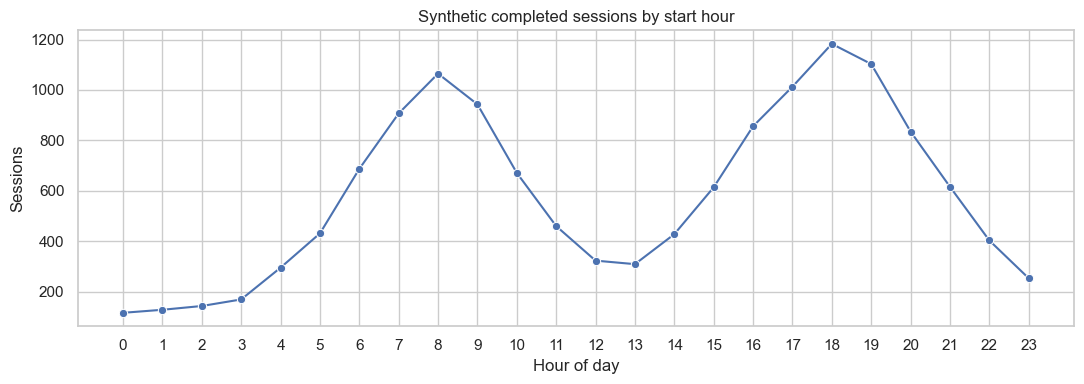

,location,sessions,energy_kwh,revenue_inr
2,HITEC City,1696,53900.73,805306.41
1,Gachibowli,1625,50687.16,761833.58
7,Madhapur,1619,51431.05,768443.72
4,Kondapur,1324,41768.79,627652.09
9,Shamshabad,1293,40650.74,608268.95
6,LB Nagar,1290,40367.22,605839.01
0,Banjara Hills,1283,40891.70,613937.56
5,Kukatpally,1281,39745.44,598704.78
8,Secunderabad,1272,41322.31,621635.68
3,Jubilee Hills,1268,40397.14,604923.63


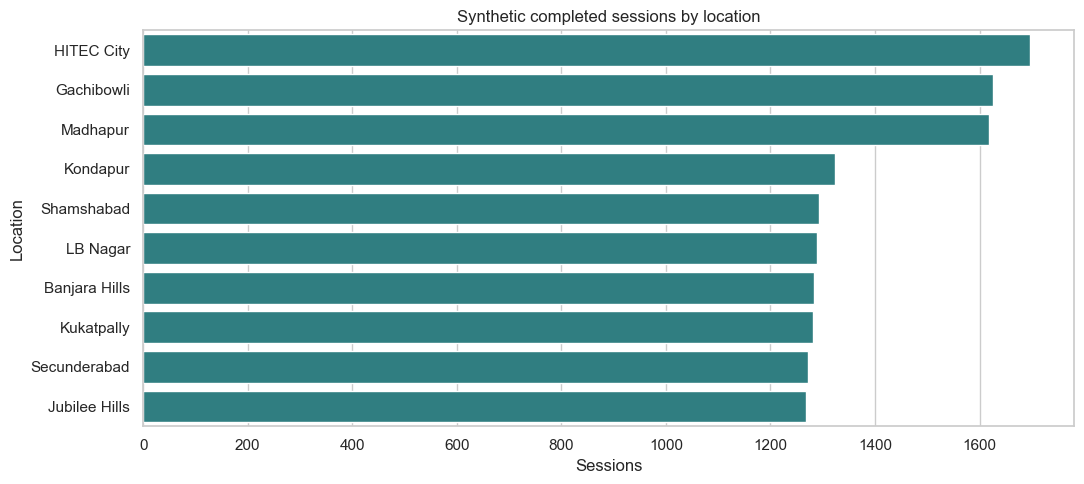

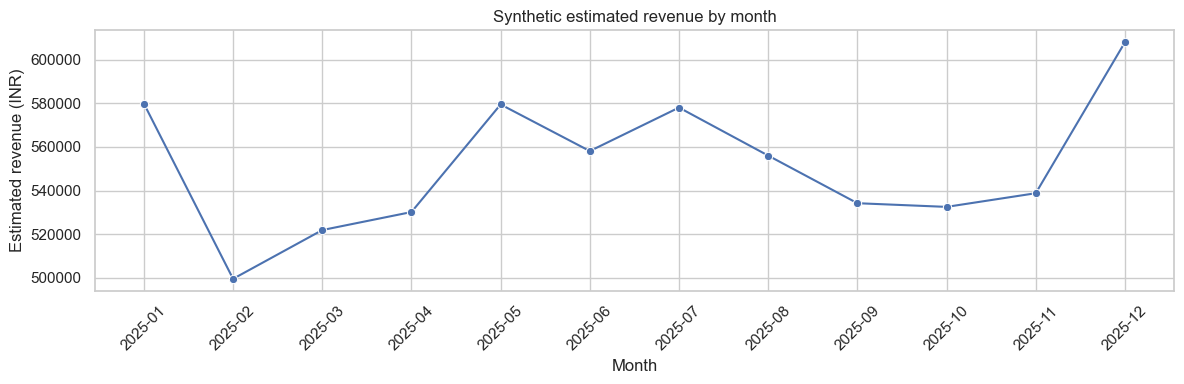

,month,sessions,energy_kwh,revenue_inr
0,2025-01,1206,38631.15,579833.73
1,2025-02,1010,33145.59,499595.50
2,2025-03,1144,34636.48,521920.56
3,2025-04,1134,35232.06,530176.74
4,2025-05,1223,38804.56,579436.66
5,2025-06,1180,37251.58,558095.94
6,2025-07,1225,38596.27,578005.50
7,2025-08,1153,36977.72,556016.33
8,2025-09,1122,35403.74,534219.41
9,2025-10,1116,35756.17,532534.27


In [4]:
hourly = completed.groupby("hour")["session_id"].nunique().reindex(range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4))
sns.lineplot(x=hourly.index, y=hourly.values, marker="o", ax=ax)
ax.set(title="Synthetic completed sessions by start hour", xlabel="Hour of day", ylabel="Sessions")
ax.set_xticks(range(24))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "demand_by_hour.png", dpi=150)
plt.show()

location_summary = (
    completed.merge(tables["stations"][["station_id", "location"]], on="station_id", validate="many_to_one")
    .groupby("location", as_index=False)
    .agg(sessions=("session_id", "nunique"), energy_kwh=("energy_kwh", "sum"), revenue_inr=("revenue_inr", "sum"))
    .sort_values("sessions", ascending=False)
)
display(location_summary.round(2))
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=location_summary, x="sessions", y="location", color="#238B8E", ax=ax)
ax.set(title="Synthetic completed sessions by location", xlabel="Sessions", ylabel="Location")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "sessions_by_location.png", dpi=150)
plt.show()

monthly_summary = (
    completed.groupby("month", as_index=False)
    .agg(sessions=("session_id", "nunique"), energy_kwh=("energy_kwh", "sum"), revenue_inr=("revenue_inr", "sum"))
    .sort_values("month")
)
fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(data=monthly_summary, x="month", y="revenue_inr", marker="o", ax=ax)
ax.set(title="Synthetic estimated revenue by month", xlabel="Month", ylabel="Estimated revenue (INR)")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "monthly_revenue.png", dpi=150)
plt.show()
monthly_summary.round(2)

## Station-hour demand dataset for a forecasting milestone

Aggregate completed sessions to station-hour, fill zero-session hours, and retain a chronological index. Any later model should use a chronological split and must be described as a model trained on synthetic practice data.

In [5]:
observed = (
    completed.assign(hour_start=completed["session_start"].dt.floor("h"))
    .groupby(["station_id", "hour_start"], as_index=False)
    .agg(completed_sessions=("session_id", "nunique"), energy_kwh=("energy_kwh", "sum"))
)
all_hours = pd.date_range(sessions["session_start"].min().normalize(), sessions["session_start"].max().normalize() + pd.Timedelta(hours=23), freq="h")
full_index = pd.MultiIndex.from_product([tables["stations"]["station_id"], all_hours], names=["station_id", "hour_start"])
hourly_station_demand = observed.set_index(["station_id", "hour_start"]).reindex(full_index, fill_value=0).reset_index()
hourly_station_demand["completed_sessions"] = hourly_station_demand["completed_sessions"].astype(int)
hourly_station_demand.to_csv(PROCESSED_DIR / "hourly_station_demand.csv", index=False)
station_summary = (
    completed.groupby("station_id", as_index=False)
    .agg(sessions=("session_id", "nunique"), energy_kwh=("energy_kwh", "sum"), revenue_inr=("revenue_inr", "sum"))
    .merge(tables["stations"][["station_id", "station_name", "location"]], on="station_id", validate="one_to_one")
    .sort_values("sessions", ascending=False)
)
display(station_summary.head(10).round(2))
print(f"Saved {len(hourly_station_demand):,} synthetic station-hour rows, including zero-demand hours.")
print("Every activity metric in this notebook is synthetic—not real Hyderabad network performance.")
assert len(hourly_station_demand) == 30 * 365 * 24

,station_id,sessions,energy_kwh,revenue_inr,station_name,location
1,ST002,578,17768.73,265643.48,Gachibowli Charging Hub 2,Gachibowli
8,ST009,575,18273.58,272731.63,HITEC City Charging Hub 3,HITEC City
2,ST003,566,18134.78,272271.83,Gachibowli Charging Hub 3,Gachibowli
6,ST007,564,17844.47,266624.07,HITEC City Charging Hub 1,HITEC City
7,ST008,557,17782.68,265950.71,HITEC City Charging Hub 2,HITEC City
5,ST006,555,17419.84,260690.87,Madhapur Charging Hub 3,Madhapur
4,ST005,544,17561.13,262509.80,Madhapur Charging Hub 2,Madhapur
3,ST004,520,16450.08,245243.05,Madhapur Charging Hub 1,Madhapur
0,ST001,481,14783.65,223918.27,Gachibowli Charging Hub 1,Gachibowli
18,ST019,462,14551.58,218755.74,Kukatpally Charging Hub 1,Kukatpally


Saved 262,800 synthetic station-hour rows, including zero-demand hours.
Every activity metric in this notebook is synthetic—not real Hyderabad network performance.
